## Cell 1 – Project Introduction

# Module 4 Mini Project: Customer Segmentation for a Retail Brand

**Technique:** K-Means Clustering Algorithm

**Dataset:** Online Retail Dataset (`OnlineRetail.csv`)

## Project Details

- **Project Name:** Customer Segmentation for a Retail Brand
- **Domain:** Machine Learning
- **Algorithm:** K-Means Clustering
- **Features:** Recency, Frequency and Monetary (RFM)

## Objective

The main objective of this project is to divide retail customers into different groups based on their purchasing behaviour.

We use the K-Means Clustering algorithm to identify four customer segments. These segments help businesses understand customer behaviour and develop better marketing strategies.

## Introduction

Customer segmentation is the process of dividing customers into groups based on their shopping habits, purchase history and spending behaviour.

In this project, we use the Online Retail dataset to analyse customer transactions and identify different types of customers.

We use RFM analysis to understand customer behaviour and K-Means clustering to create customer groups.

## Cell 2 – Understanding RFM Analysis

What is RFM Analysis?

RFM is a technique used to understand customer purchasing behaviour using three important factors.
Feature	Meaning	Explanation
Recency	Last purchase	How recently a customer purchased something
Frequency	Number of orders	How many different orders a customer placed
Monetary	Total spending	How much money a customer spent

Example:
- Customer A purchased recently, ordered frequently and spent more money.
- Customer B purchased a long time ago, ordered only once and spent less money.
Customer A may be a loyal customer, while Customer B may need a special offer to return.

## Cell 3 – Import Libraries

In [24]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Cell 4 – Load the Dataset

In [25]:
# Step 1 – Download the dataset automatically

import urllib.request

# Dataset download link
url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

# Download ZIP file
urllib.request.urlretrieve(url, "OnlineRetail.zip")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [26]:
# Step 2 – Extract the ZIP file

import zipfile
import os

# Extract downloaded ZIP file
with zipfile.ZipFile("OnlineRetail.zip", "r") as zip_ref:
    zip_ref.extractall("OnlineRetail_Data")

print("Dataset extracted successfully!")

print("Extracted Files:")
print(os.listdir("OnlineRetail_Data"))

Dataset extracted successfully!
Extracted Files:
['Online Retail.xlsx']


In [27]:
# Step 3 – Load the dataset

import pandas as pd
import os

# Find the Excel file
files = os.listdir("OnlineRetail_Data")

excel_file = [
    file for file in files
    if file.endswith(".xlsx")
][0]

# Load dataset
df = pd.read_excel(
    os.path.join("OnlineRetail_Data", excel_file)
)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [28]:
# Step 4 – Verify the dataset

# Check columns
print("Dataset Columns:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Dataset information
print("\nDataset Information:")
df.info()

Dataset Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2),

## Cell 5 – Understand the Dataset

In [29]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [30]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [31]:
# Statistical summary
display(df.describe())

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


## Cell 6 – Exploratory Data Analysis (EDA)

In [32]:
# Number of customers and transactions

print("Total Transactions:", len(df))

print("Unique Customers:", df["CustomerID"].nunique())

print("Unique Products:", df["StockCode"].nunique())

print("Number of Countries:", df["Country"].nunique())

Total Transactions: 541909
Unique Customers: 4372
Unique Products: 4070
Number of Countries: 38


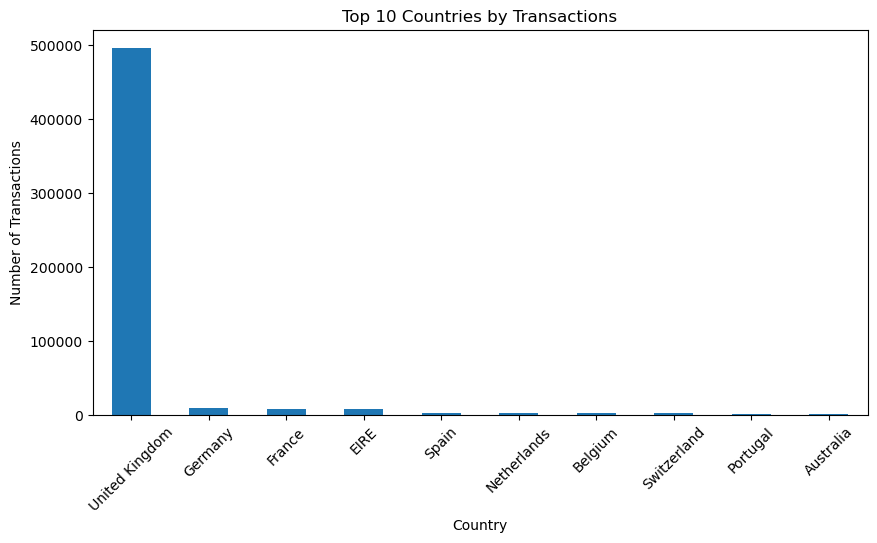

In [33]:
# Top 10 countries by transactions

country_count = df["Country"].value_counts().head(10)

plt.figure(figsize=(10, 5))

country_count.plot(kind="bar")

plt.title("Top 10 Countries by Transactions")
plt.xlabel("Country")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.show()

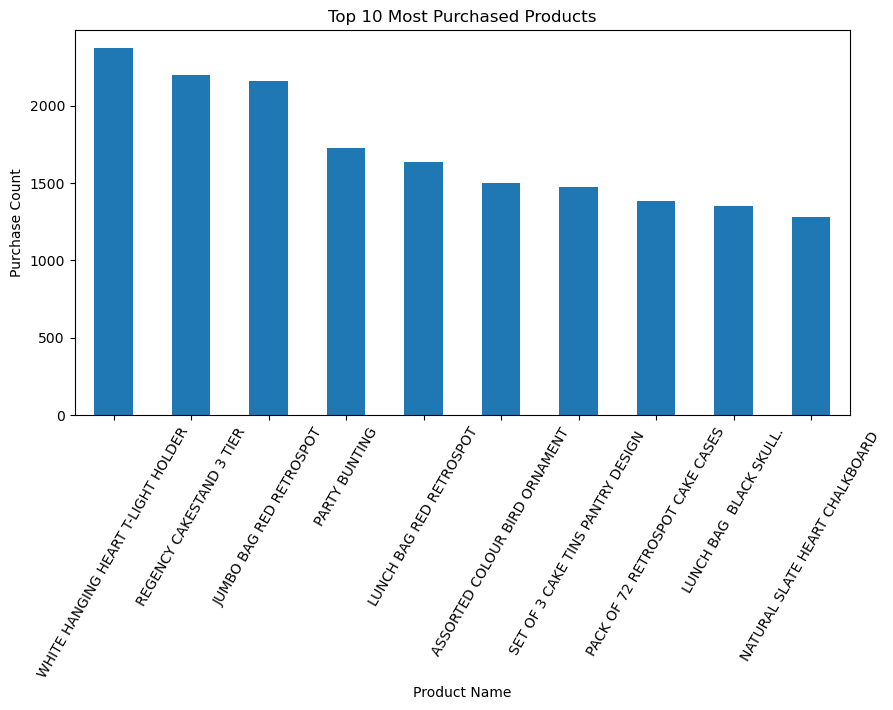

In [34]:
# Most frequently purchased products

top_products = df["Description"].value_counts().head(10)

plt.figure(figsize=(10, 5))

top_products.plot(kind="bar")

plt.title("Top 10 Most Purchased Products")
plt.xlabel("Product Name")
plt.ylabel("Purchase Count")
plt.xticks(rotation=60)

plt.show()

## Cell 7 – Data Cleaning

In [35]:
# Convert InvoiceDate into datetime format

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

# Remove missing customer IDs and invoice dates

data = df.dropna(
    subset=["CustomerID", "InvoiceDate"]
).copy()

# Remove cancelled invoices

data = data[
    ~data["InvoiceNo"].astype(str).str.startswith("C")
]

# Remove invalid quantities and prices

data = data[
    (data["Quantity"] > 0) &
    (data["UnitPrice"] > 0)
]

# Convert CustomerID into integer

data["CustomerID"] = data["CustomerID"].astype(int)

# Calculate total sales

data["Sales"] = data["Quantity"] * data["UnitPrice"]

print("Data Cleaning Completed!")

print("Cleaned Dataset Shape:", data.shape)

print("Total Customers:", data["CustomerID"].nunique())

display(data.head())

Data Cleaning Completed!
Cleaned Dataset Shape: (397884, 9)
Total Customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## Cell 8 – Calculate RFM Values

In [36]:
# Set the reference date

snapshot_date = data["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM values

rfm = data.groupby("CustomerID").agg({

    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,

    "InvoiceNo": "nunique",

    "Sales": "sum"

})

# Rename columns

rfm.rename(columns={

    "InvoiceDate": "Recency",

    "InvoiceNo": "Frequency",

    "Sales": "Monetary"

}, inplace=True)

# Display RFM data

display(rfm.head())

print("Total Customers:", len(rfm))

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


Total Customers: 4338


## Cell 9 – Understand RFM Data

In [37]:
# Statistical summary of RFM

display(rfm.describe().round(2))

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02


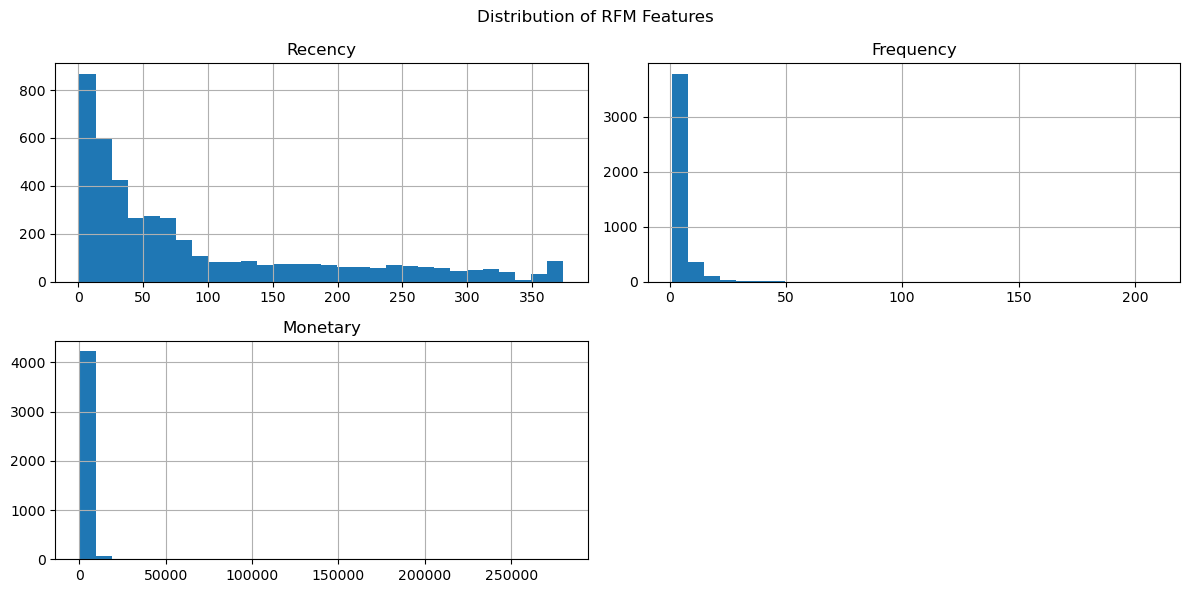

In [38]:
# Create three histograms

rfm[["Recency", "Frequency", "Monetary"]].hist(
    figsize=(12, 6),
    bins=30
)

plt.suptitle("Distribution of RFM Features")

plt.tight_layout()

plt.show()

## Cell 10 – Data Transformation and Scaling

In [39]:
# Machine Learning libraries
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [40]:
# Select RFM features

features = ["Recency", "Frequency", "Monetary"]

# Apply log transformation

X_log = np.log1p(rfm[features])

# Apply feature scaling

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

print("Data Transformation Completed!")

print("Scaled Data Shape:", X_scaled.shape)

Data Transformation Completed!
Scaled Data Shape: (4338, 3)


## Cell 11 – Apply K-Means Clustering

In [41]:
import os
import warnings

# Avoid Joblib CPU core warning
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

# Suppress the specific Joblib warning
warnings.filterwarnings(
    "ignore",
    message="Could not find the number of physical cores.*"
)

# Create K-Means model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Train model and assign clusters
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Completed Successfully!")

# Display customer clusters
display(rfm.head())

K-Means Clustering Completed Successfully!


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,2
12347,2,7,4310.00,1
12348,75,4,1797.24,2
12349,19,1,1757.55,0
12350,310,1,334.40,3


## Cell 12 – Evaluate the Model

In [42]:
# Calculate silhouette score

score = silhouette_score(X_scaled, rfm["Cluster"])

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.337


## Cell 13 – Analyse Customer Segments

In [43]:
# Create cluster summary

segment_summary = rfm.groupby("Cluster").agg(

    Customers=("Recency", "count"),

    Average_Recency=("Recency", "mean"),

    Average_Frequency=("Frequency", "mean"),

    Average_Monetary=("Monetary", "mean"),

    Total_Revenue=("Monetary", "sum")

).round(2)

# Calculate customer percentage

segment_summary["Customer_Share_%"] = (

    segment_summary["Customers"] / len(rfm) * 100

).round(2)

# Calculate revenue percentage

segment_summary["Revenue_Share_%"] = (

    segment_summary["Total_Revenue"] /
    rfm["Monetary"].sum() * 100

).round(2)

display(segment_summary)

,Customers,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue,Customer_Share_%,Revenue_Share_%
Cluster,,,,,,,
0,837,18.12,2.15,551.82,461872.95,19.29,5.18
1,716,12.13,13.71,8074.27,5781175.08,16.51,64.87
2,1173,71.08,4.08,1802.83,2114718.42,27.04,23.73
3,1612,182.50,1.32,343.45,553641.45,37.16,6.21


## Cell 14 – Visualise Customer Segments

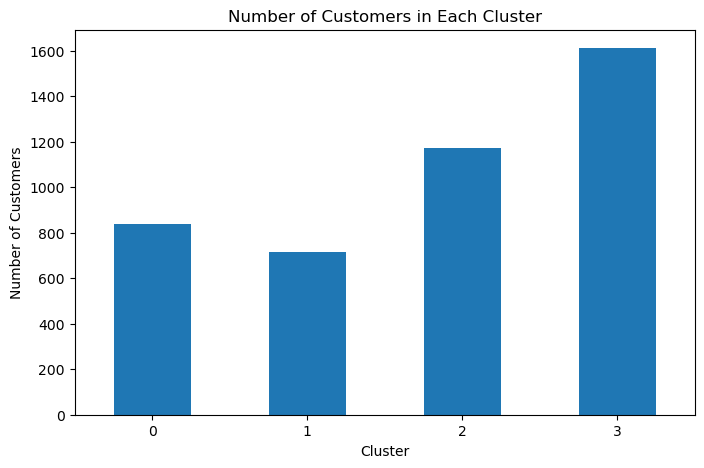

In [44]:
# Number of customers in each cluster

plt.figure(figsize=(8, 5))

segment_summary["Customers"].plot(kind="bar")

plt.title("Number of Customers in Each Cluster")

plt.xlabel("Cluster")

plt.ylabel("Number of Customers")

plt.xticks(rotation=0)

plt.show()

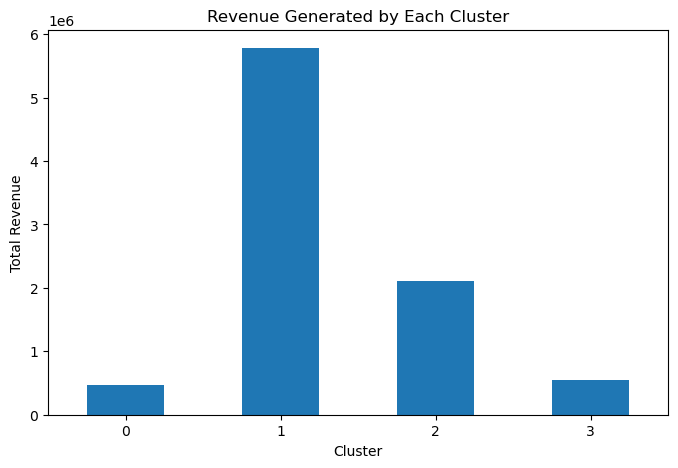

In [45]:
# Revenue generated by each cluster

plt.figure(figsize=(8, 5))

segment_summary["Total_Revenue"].plot(kind="bar")

plt.title("Revenue Generated by Each Cluster")

plt.xlabel("Cluster")

plt.ylabel("Total Revenue")

plt.xticks(rotation=0)

plt.show()

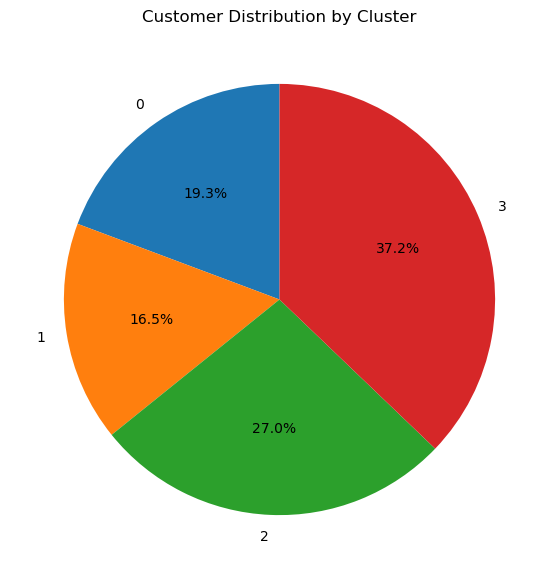

In [46]:
# Customer distribution

plt.figure(figsize=(7, 7))

plt.pie(
    segment_summary["Customers"],
    labels=segment_summary.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Distribution by Cluster")

plt.show()

## Cell 15 – Interpret Customer Segments

The K-Means algorithm creates cluster numbers automatically. These numbers do not represent customer rankings.

We interpret each cluster by checking its Recency, Frequency and Monetary values.
Customer Segment	Customer Behaviour	Marketing Strategy
Champions / VIP	Recent purchases, high frequency and high spending	Loyalty rewards, exclusive offers and early access
Loyal Customers	Regular purchases and good spending	Special discounts, bundles and cross-selling
New / Occasional	Recent purchase but low frequency and spending	Welcome offers and product recommendations
At-Risk / Dormant	Long time since last purchase and low activity	Win-back emails and limited-time offers

Important: The actual cluster numbers must be mapped to these names after checking your cluster summary. Do not assume that Cluster 0 is always the VIP group.

## Cell 16 – Save Final Results

In [47]:
# Save customer segmentation results

rfm.to_csv("customer_segments.csv", index=True)

# Save cluster summary

segment_summary.to_csv("segment_summary.csv")

print("Files Saved Successfully!")

print("1. customer_segments.csv")

print("2. segment_summary.csv")

Files Saved Successfully!
1. customer_segments.csv
2. segment_summary.csv


## Cell 17 – Final Conclusion

Conclusion

In this project, we successfully performed customer segmentation using the K-Means Clustering algorithm and RFM analysis.

We used the Online Retail dataset to understand customer purchasing behaviour through three important features: Recency, Frequency and Monetary.

After cleaning the dataset, we calculated RFM values, applied data transformation and scaling, and divided customers into four clusters using K-Means.

The analysis helps identify different customer groups, such as Champions, Loyal Customers, New or Occasional Customers, and At-Risk Customers.

Based on these groups, businesses can create targeted marketing strategies, improve customer relationships, increase customer retention and improve sales.

Final Outcome: Customer segmentation helps retail businesses understand their customers and make better marketing decisions.

## Cell 18 – Limitations and Future Scope

## Limitations
1. The project uses historical transaction data.
2. The Monetary feature represents sales, not actual profit.
3. Four clusters are selected for this project, but other cluster counts may provide better results.
4. Customer behaviour may change over time.
5. The dataset ends in 2011, so the results are for learning purposes and do not represent current retail customers.
## Future Scope
1. Compare different numbers of clusters using the Elbow Method and Silhouette Score.
2. Build an interactive customer segmentation dashboard using Streamlit or Power BI.
3. Develop personalised marketing recommendations for each customer group.
4. Use updated retail transaction data for more relevant business insights.
5. Combine RFM analysis with other machine learning techniques.